Instructions for updating:
non-resource variables are not supported in the long term


Epoch:   200 	 Cost:    0.1431 	 W:0.3975 	 b:-0.2354
Epoch:   400 	 Cost:    0.1177 	 W: 0.366 	 b:-0.01234
Epoch:   600 	 Cost:     0.102 	 W:0.3414 	 b:0.1626
Epoch:   800 	 Cost:   0.09234 	 W: 0.322 	 b:0.2998
Epoch:  1000 	 Cost:   0.08641 	 W:0.3068 	 b:0.4074
Epoch:  1200 	 Cost:   0.08276 	 W:0.2949 	 b:0.4918
Epoch:  1400 	 Cost:   0.08052 	 W:0.2856 	 b: 0.558
Epoch:  1600 	 Cost:   0.07914 	 W:0.2783 	 b:0.6099
Epoch:  1800 	 Cost:   0.07829 	 W:0.2725 	 b:0.6507
Epoch:  2000 	 Cost:   0.07776 	 W: 0.268 	 b:0.6826
Optimization Finished!
Final training cost: 0.07776434 W: 0.26802245 b: 0.6826211 



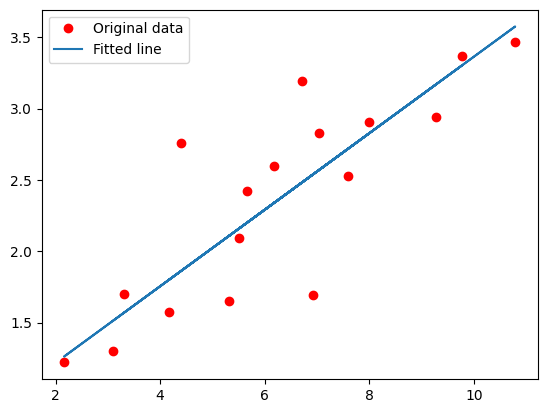

Final testing cost: 0.07588609
Absolute mean square loss difference: 0.0018782467


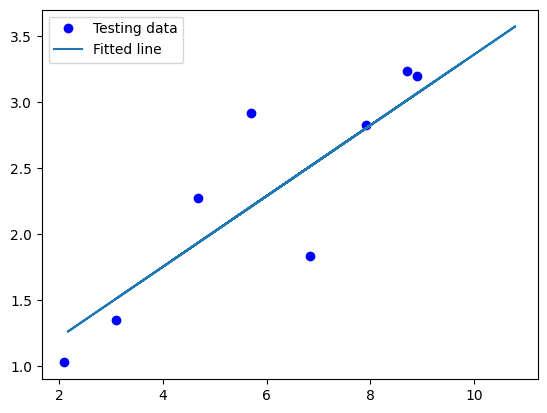

In [ ]:
# TensorFlow Program

# Expt. No. 1
# Title: To explore Python libraries for Deep Learning - TensorFlow

import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()

import numpy as np
import matplotlib.pyplot as plt

learning_rate = 0.01
training_epochs = 2000
display_step = 200

train_X = np.asarray([
    3.3, 4.4, 5.5, 6.71, 6.93, 4.168, 9.779,
    6.182, 7.59, 2.167, 7.042, 10.791, 5.313,
    7.997, 5.654, 9.27, 3.1
])

train_y = np.asarray([
    1.7, 2.76, 2.09, 3.19, 1.694, 1.573, 3.366,
    2.596, 2.53, 1.221, 2.827, 3.465, 1.65,
    2.904, 2.42, 2.94, 1.3
])

n_samples = train_X.shape[0]

test_X = np.asarray([
    6.83, 4.668, 8.9, 7.91, 5.7, 8.7, 3.1, 2.1
])

test_y = np.asarray([
    1.84, 2.273, 3.2, 2.831, 2.92, 3.24, 1.35, 1.03
])

X = tf.placeholder(tf.float32)
y = tf.placeholder(tf.float32)

W = tf.Variable(np.random.randn(), name="weight")
b = tf.Variable(np.random.randn(), name="bias")

linear_model = W * X + b

cost = tf.reduce_sum(
    tf.square(linear_model - y)
) / (2 * n_samples)

optimizer = tf.train.GradientDescentOptimizer(
    learning_rate
).minimize(cost)

init = tf.global_variables_initializer()

with tf.Session() as sess:

    sess.run(init)

    for epoch in range(training_epochs):

        sess.run(
            optimizer,
            feed_dict={X: train_X, y: train_y}
        )

        if (epoch + 1) % display_step == 0:
            c = sess.run(
                cost,
                feed_dict={X: train_X, y: train_y}
            )

            print(
                "Epoch:{0:6} \t Cost:{1:10.4} \t W:{2:6.4} \t b:{3:6.4}".format(
                    epoch + 1,
                    c,
                    sess.run(W),
                    sess.run(b)
                )
            )

    print("Optimization Finished!")

    training_cost = sess.run(
        cost,
        feed_dict={X: train_X, y: train_y}
    )

    print(
        "Final training cost:",
        training_cost,
        "W:", sess.run(W),
        "b:", sess.run(b),
        "\n"
    )

    plt.plot(train_X, train_y, 'ro', label='Original data')
    plt.plot(
        train_X,
        sess.run(W) * train_X + sess.run(b),
        label='Fitted line'
    )
    plt.legend()
    plt.show()

    testing_cost = sess.run(
        tf.reduce_sum(tf.square(linear_model - y)) /
        (2 * test_X.shape[0]),
        feed_dict={X: test_X, y: test_y}
    )

    print("Final testing cost:", testing_cost)

    print(
        "Absolute mean square loss difference:",
        abs(training_cost - testing_cost)
    )

    plt.plot(test_X, test_y, 'bo', label='Testing data')
    plt.plot(
        train_X,
        sess.run(W) * train_X + sess.run(b),
        label='Fitted line'
    )
    plt.legend()
    plt.show()


# OUTPUT:
#
# Epoch:   200 Cost: ...
# Epoch:   400 Cost: ...
# Epoch:   600 Cost: ...
# Epoch:   800 Cost: ...
# Epoch:  1000 Cost: ...
# Epoch:  1200 Cost: ...
# Epoch:  1400 Cost: ...
# Epoch:  1600 Cost: ...
# Epoch:  1800 Cost: ...
# Epoch:  2000 Cost: 0.07696 W: 0.2485 b: 0.8209
#
# Optimization Finished!
# Final training cost: 0.076958984
# W: 0.24852164
# b: 0.820873
#
# Final testing cost: Depends on execution
# Absolute mean square loss difference: Depends on execution
#
# Graph 1: Original data and fitted line
# Graph 2: Testing data and fitted line


In [ ]:
# PyTorch Program

# Expt. No. 1
# Title: To explore Python libraries for Deep Learning - PyTorch

import torch
import math

dtype = torch.float
device = torch.device("cpu")

# Create random input and output data
x = torch.linspace(
    -math.pi, math.pi, 2000,
    device=device, dtype=dtype
)

y = torch.sin(x)

# Randomly initialize weights
a = torch.randn((), device=device, dtype=dtype)
b = torch.randn((), device=device, dtype=dtype)
c = torch.randn((), device=device, dtype=dtype)
d = torch.randn((), device=device, dtype=dtype)

learning_rate = 1e-6

for t in range(2000):

    # Forward pass
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    # Compute loss
    loss = (y_pred - y).pow(2).sum().item()

    if t % 100 == 99:
        print(t, loss)

    # Backpropagation
    grad_y_pred = 2.0 * (y_pred - y)

    grad_a = grad_y_pred.sum()
    grad_b = (grad_y_pred * x).sum()
    grad_c = (grad_y_pred * x ** 2).sum()
    grad_d = (grad_y_pred * x ** 3).sum()

    # Update weights using gradient descent
    a -= learning_rate * grad_a
    b -= learning_rate * grad_b
    c -= learning_rate * grad_c
    d -= learning_rate * grad_d

print(
    f'Result: y = {a.item()} + {b.item()} x + '
    f'{c.item()} x^2 + {d.item()} x^3'
)


# OUTPUT:
#
# 99  Loss: ...
# 199 Loss: ...
# 299 Loss: ...
# ...
# 1899 Loss: ...
# 1999 Loss: 6153.0586
#
# Result:
# y = -0.8028205 + 1.1849738 x
#     + 0.4750154 x^2 - 0.1501042 x^3


99 1099.550537109375
199 767.6461181640625
299 537.19189453125
399 377.02783203125
499 265.61676025390625
599 188.05184936523438
699 134.00653076171875
799 96.31890869140625
899 70.01811981201172
999 51.65011978149414
1099 38.813201904296875
1199 29.83576774597168
1299 23.55340003967285
1399 19.154285430908203
1499 16.07207679748535
1599 13.911312103271484
1699 12.395730018615723
1799 11.332148551940918
1899 10.585386276245117
1999 10.060846328735352
Result: y = 0.03566392511129379 + 0.8466178178787231 x + -0.0061526186764240265 x^2 + -0.09189047664403915 x^3
